In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

In [2]:
df = pd.read_excel("TugasBagianA_Bersih.xlsx", sheet_name="Data_Bersih")

df["Purchase_Date"] = pd.to_datetime(df["Purchase_Date"])
df["Month"] = df["Purchase_Date"].dt.month
df["Day_of_Month"] = df["Purchase_Date"].dt.day

df.head()

,Transaction_ID,Customer_ID,Age,Gender,City,Region,Membership_Level,Product_Category,Product_Name,Quantity,...,Discount_Percentage,Purchase_Amount,Payment_Method,Store_Type,Purchase_Date,Purchase_Hour,Purchase_Day,Customer_Satisfaction,Month,Day_of_Month
0,TRX-000001,CUST-02118,35,Female,Jakarta,Jabodetabek,Gold,Groceries,Assorted Snack Box,5,...,0.00,520000,QRIS,Online App,2026-01-01,3,Thursday,3,1,1
1,TRX-000002,CUST-03099,26,Male,Yogyakarta,Central Java,Basic,Home & Living,Air Purifier Mini,2,...,0.20,486400,Credit Card,Online App,2026-01-01,5,Thursday,1,1,1
2,TRX-000003,CUST-01259,37,Female,Sidoarjo,East Java,Basic,Fashion,Casual Chino Pants,2,...,0.10,768600,E-Wallet,Online App,2026-01-01,8,Thursday,1,1,1
3,TRX-000004,CUST-02153,33,Male,Medan,Sumatera,Premium,Home & Living,Ceramic Coffee Dripper,3,...,0.05,1214100,E-Wallet,Official Web,2026-01-01,8,Thursday,4,1,1
4,TRX-000005,CUST-00942,31,Male,Tangerang,Jabodetabek,Basic,Beauty & Health,Hydrating Facial Cleanser,3,...,0.05,262200,Debit Card,Flagship Store,2026-01-01,8,Thursday,5,1,1


In [3]:
print("Ukuran data :", df.shape)
print("Missing     :", df.isnull().sum().sum())
print("Maks diskon :", df["Discount_Percentage"].max())

Ukuran data : (9557, 21)
Missing     : 0
Maks diskon : 0.5


In [4]:
import os
import matplotlib.dates as mdates

os.makedirs("charts", exist_ok=True)

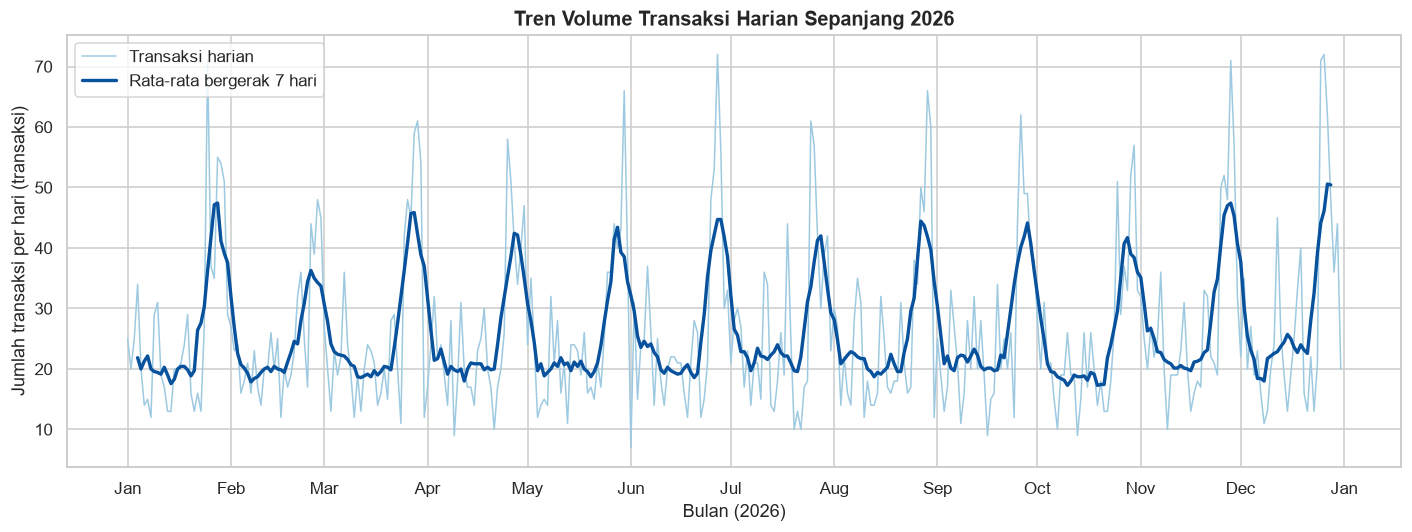

In [5]:
harian = df.groupby("Purchase_Date").size().rename("Transaksi").reset_index()
harian["MA7"] = harian["Transaksi"].rolling(7, center=True).mean()

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(harian["Purchase_Date"], harian["Transaksi"], color="#9ecae1", linewidth=1, label="Transaksi harian")
ax.plot(harian["Purchase_Date"], harian["MA7"], color="#08519c", linewidth=2.2, label="Rata-rata bergerak 7 hari")
ax.set_title("Tren Volume Transaksi Harian Sepanjang 2026", fontsize=13, fontweight="bold")
ax.set_xlabel("Bulan (2026)")
ax.set_ylabel("Jumlah transaksi per hari (transaksi)")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.legend()
plt.tight_layout()
plt.savefig("charts/H1_tren_harian.png", dpi=300, bbox_inches="tight")
plt.show()

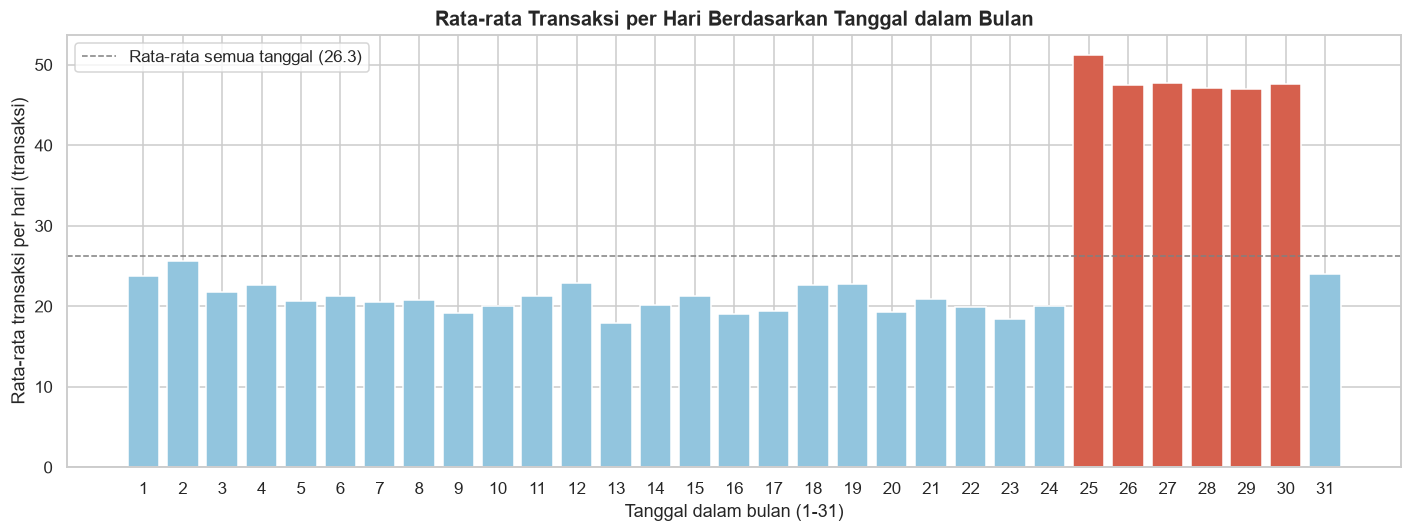

In [6]:
per_tanggal = harian.groupby(harian["Purchase_Date"].dt.day)["Transaksi"].mean()
batas = per_tanggal.mean() * 1.15
warna = ["#d6604d" if v >= batas else "#92c5de" for v in per_tanggal.values]

fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(per_tanggal.index, per_tanggal.values, color=warna)
ax.axhline(per_tanggal.mean(), color="gray", linestyle="--", linewidth=1,
           label=f"Rata-rata semua tanggal ({per_tanggal.mean():.1f})")
ax.set_title("Rata-rata Transaksi per Hari Berdasarkan Tanggal dalam Bulan", fontsize=13, fontweight="bold")
ax.set_xlabel("Tanggal dalam bulan (1-31)")
ax.set_ylabel("Rata-rata transaksi per hari (transaksi)")
ax.set_xticks(range(1, 32))
ax.legend()
plt.tight_layout()
plt.savefig("charts/H1_tanggal_dalam_bulan.png", dpi=300, bbox_inches="tight")
plt.show()

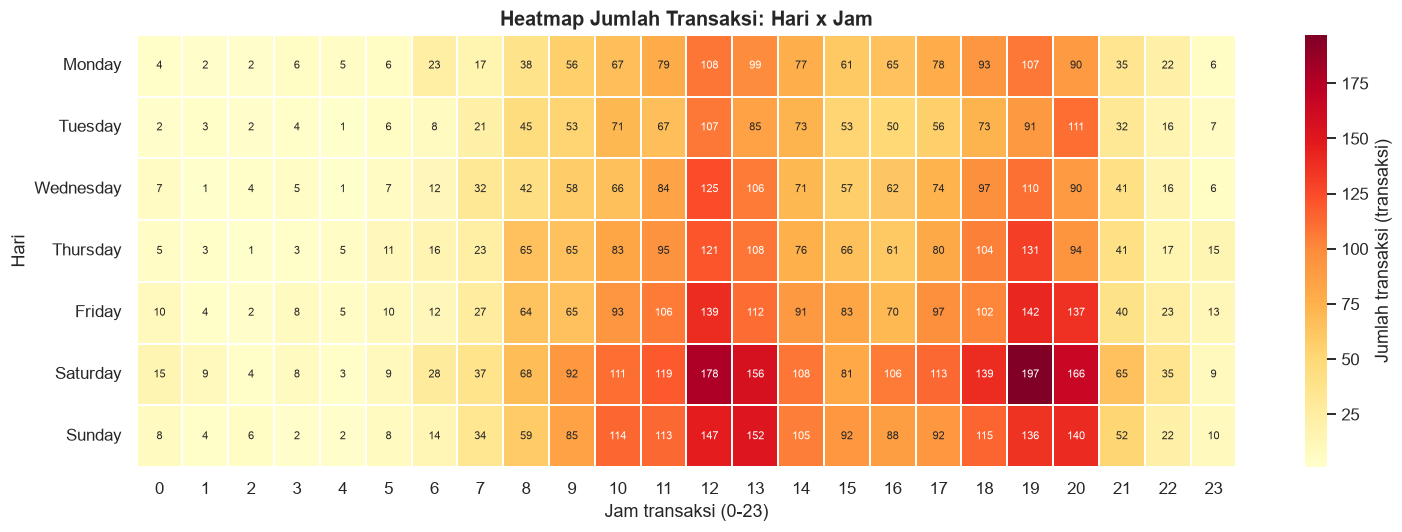

In [7]:
urutan_hari = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
pivot = (df.pivot_table(index="Purchase_Day", columns="Purchase_Hour",
                        values="Transaction_ID", aggfunc="count", fill_value=0)
           .reindex(urutan_hari).reindex(columns=range(24), fill_value=0))

fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(pivot, cmap="YlOrRd", annot=True, fmt="d", annot_kws={"size": 7}, linewidths=0.3,
            cbar_kws={"label": "Jumlah transaksi (transaksi)"}, ax=ax)
ax.set_title("Heatmap Jumlah Transaksi: Hari x Jam", fontsize=13, fontweight="bold")
ax.set_xlabel("Jam transaksi (0-23)")
ax.set_ylabel("Hari")
plt.tight_layout()
plt.savefig("charts/H1_heatmap_hari_jam.png", dpi=300, bbox_inches="tight")
plt.show()